## 1. Configuração do ambiente e importação das bibliotecas

As bibliotecas utilizadas nesta etapa são:
- pandas: leitura e manipulação do dataset;
- matplotlib e seaborn: criação de gráficos.
As demais bibliotecas de Machine Learning serão importadas nas etapas em que forem necessárias.

Instalação: as dependências devem ser instaladas pelo requirements.txt do projeto, e não repetidamente dentro do notebook.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 2. Carregamento do dataset

O arquivo spam_ham_dataset.csv deve estar na pasta data/ do projeto. Como o notebook está na pasta notebooks/, o código considera tanto a execução a partir da raiz do projeto quanto a execução a partir da própria pasta de notebooks.

In [9]:
# Localiza o arquivo do dataset
caminhos_dataset = [
    Path("data/spam_ham_dataset.csv"),
    Path("../data/spam_ham_dataset.csv")
]

caminho_dataset = next(
    (caminho for caminho in caminhos_dataset if caminho.exists()),
    None
)

if caminho_dataset is None:
    raise FileNotFoundError(
        "Dataset não encontrado. Verifique se o arquivo "
        "'spam_ham_dataset.csv' está na pasta 'data/'."
    )

# Carrega o dataset
df = pd.read_csv(caminho_dataset)

# Remove uma possível coluna de índice salva no arquivo CSV
df = df.loc[:, ~df.columns.str.contains(r"^Unnamed")]

print(f"Dataset carregado: {len(df)} registros")
display(df.head())

Dataset carregado: 5171 registros


,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0


## 3. Conhecendo a estrutura dos dados

Nesta etapa, verificamos as colunas, os tipos de dados e a quantidade de registros. Também confirmamos se as colunas necessárias para a classificação estão presentes.

In [10]:
# Informações gerais do dataset
df.info()

print("\nColunas disponíveis:")
print(df.columns.tolist())

# Verifica se as colunas necessárias existem
colunas_necessarias = {"label", "text"}
colunas_ausentes = colunas_necessarias - set(df.columns)

if colunas_ausentes:
    raise ValueError(
        f"Colunas necessárias não encontradas: {sorted(colunas_ausentes)}"
    )

<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   label      5171 non-null   str  
 1   text       5171 non-null   str  
 2   label_num  5171 non-null   int64
dtypes: int64(1), str(2)
memory usage: 121.3 KB

Colunas disponíveis:
['label', 'text', 'label_num']


## 4. Análise exploratória dos dados

A análise exploratória ajuda a identificar problemas que podem afetar o treinamento, como valores ausentes, mensagens duplicadas e diferenças na quantidade de exemplos de cada classe.

Valores ausentes por coluna:


label    0
text     0
dtype: int64

Mensagens duplicadas: 178
Quantidade de mensagens por classe:


label
ham     3672
spam    1499
Name: count, dtype: int64


Proporção das classes (%):


label
ham     71.01
spam    28.99
Name: count, dtype: float64

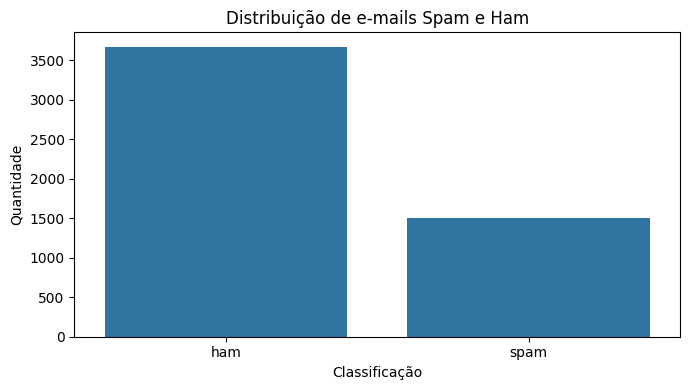

In [11]:
# Verificação de valores ausentes

valores_ausentes = df[["label", "text"]].isnull().sum()

print("Valores ausentes por coluna:")
display(valores_ausentes)

# Verificação de mensagens duplicadas

quantidade_duplicados = df.duplicated(subset=["text"]).sum()
print(f"Mensagens duplicadas: {quantidade_duplicados}")

# Distribuição das classes

distribuicao_classes = df["label"].value_counts()

print("Quantidade de mensagens por classe:")
display(distribuicao_classes)

print("\nProporção das classes (%):")
display((distribuicao_classes / len(df) * 100).round(2))

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="label", order=["ham", "spam"])

plt.title("Distribuição de e-mails Spam e Ham")
plt.xlabel("Classificação")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.show()